# Introducción a Series de Tiempo y Estacionariedad

## ¿Qué es una serie de tiempo?
Es un conjunto de observaciones registradas a lo largo del tiempo, por ejemplo:

- Precios de acciones
- Temperaturas
- Demanda de energía
- Ventas

El objetivo es **analizar el pasado para predecir el futuro**.

---

## Características importantes de una serie de tiempo

### Tendencia (Trend)
Comportamiento de largo plazo:

- Positiva: la serie aumenta con el tiempo.
- Negativa: la serie disminuye.

### Estacionalidad (Seasonality)
Patrones que se repiten en intervalos fijos:

- Ventas altas cada diciembre.
- Mayor consumo eléctrico en verano.

### Ciclicidad (Cyclicality)
Patrones repetitivos pero **sin un período fijo**.

### Ruido Blanco (White Noise)
Serie completamente aleatoria:

- Cada observación es independiente de las anteriores.
- No existe un patrón predecible.

---

# Estacionariedad

Para modelar una serie con ARIMA, la serie debe ser **estacionaria**, es decir, sus propiedades estadísticas no cambian con el tiempo.

Una serie estacionaria cumple:

1. **Media constante** (sin tendencia).
2. **Varianza constante**.
3. **Autocorrelación constante**.

---

# División Train-Test en Series de Tiempo

A diferencia del Machine Learning tradicional, no se pueden mezclar los datos aleatoriamente.

Se debe respetar el orden temporal:

```text
Pasado ───────────────► Futuro
Entrenamiento         Prueba
```

- **Train:** observaciones antiguas.
- **Test:** observaciones más recientes.

Esto permite evaluar qué tan bien el modelo predice datos futuros.

---

# Idea principal

```text
Serie de tiempo
        ↓
Analizar patrones (tendencia, estacionalidad)
        ↓
Verificar estacionariedad
        ↓
Entrenar modelo con datos pasados
        ↓
Pronosticar el futuro
```

# Exploración de una Serie de Tiempo

En este ejercicio se analiza la producción mensual de dulces en Estados Unidos (`IPG3113N`) entre 1972 y 2018.

La variable representa la producción de azúcar y productos de confitería como un porcentaje de la producción de enero de 2012:

- `100` → misma producción que en enero de 2012.
- `120` → producción un 20% mayor.
- `80` → producción un 20% menor.

## Objetivos

1. Cargar la serie de tiempo desde un archivo CSV.
2. Convertir la columna de fechas en el índice.
3. Graficar la serie para identificar:

- **Tendencia** (si la producción aumenta o disminuye en el tiempo).
- **Estacionalidad** (patrones que se repiten cada año).

## Código

```python
import pandas as pd
import matplotlib.pyplot as plt

candy = pd.read_csv(
    'candy_production.csv',
    index_col='date',
    parse_dates=True
)

fig, ax1 = plt.subplots(figsize=(12,5))
candy.plot(ax=ax1)
plt.show()
```

## Idea principal

Antes de construir un modelo de pronóstico, siempre es recomendable **explorar visualmente la serie** para detectar patrones, tendencias y estacionalidad.

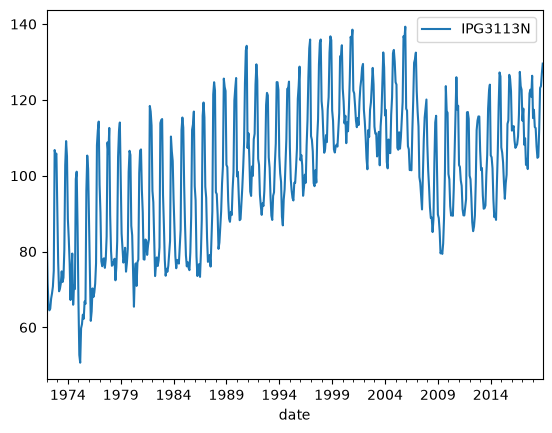

In [1]:
# Import modules
import pandas as pd
import matplotlib.pyplot as plt

# Load in the time series
candy = pd.read_csv('candy_production.csv', 
                 index_col='date', 
                 parse_dates=True)

# Plot and show the time series on axis ax1
fig, ax1 = plt.subplots()
candy.plot(ax=ax1)
plt.show()

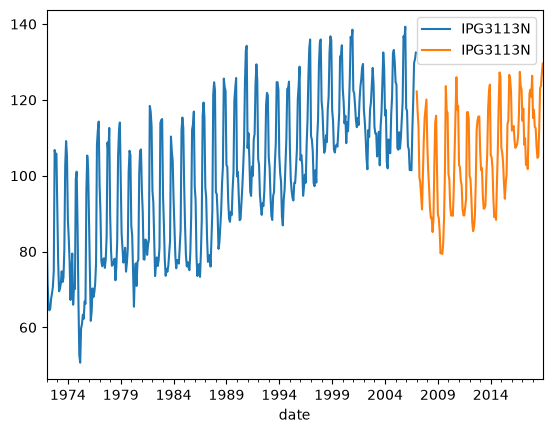

In [2]:
# Split the data into a train and test set
candy_train = candy.loc[:'2006']
candy_test = candy.loc['2007':]

# Create an axis
fig, ax = plt.subplots()

# Plot the train and test sets on the axis ax
candy_train.plot(ax=ax)
candy_test.plot(ax=ax)
plt.show()

# Pregunta 1

La gráfica superior muestra el precio de cierre de la acción de Amazon.

**¿El precio de la acción es estacionario?**

- ☐ No, porque la dinámica cambia con el tiempo.
- ☐ No, porque la varianza cambia con el tiempo.
- ✅ No, porque la gráfica presenta una tendencia.
- ☐ Sí, la serie parece estacionaria.

---

# Pregunta 2

La gráfica del medio muestra los retornos diarios (porcentaje de cambio) de la acción de Amazon.

**¿Los retornos son estacionarios?**

- ☐ No, porque la dinámica cambia con el tiempo.
- ☐ No, porque la varianza cambia con el tiempo.
- ☐ No, porque la gráfica presenta una tendencia.
- ✅ Sí, la serie parece estacionaria.

---

# Pregunta 3

La gráfica inferior muestra el número de terremotos de magnitud 7.0 o superior por año.

**¿La serie es estacionaria?**

- ☐ No, porque la dinámica cambia con el tiempo.
- ☐ No, porque la varianza cambia con el tiempo.
- ☐ No, porque la gráfica presenta una tendencia.
- ✅ Sí, la serie parece estacionaria.

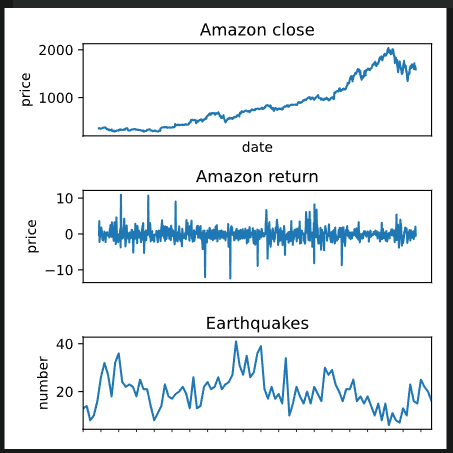

# Estacionariedad y Transformación de Series de Tiempo

## Prueba Augmented Dickey-Fuller (ADF)

La prueba **ADF** se utiliza para determinar si una serie es estacionaria.

### Hipótesis

- **H₀:** La serie es no estacionaria (tiene raíz unitaria o tendencia).
- **H₁:** La serie es estacionaria.

### Interpretación

- **p-value < 0.05**
  
  ⇒ Se rechaza H₀.

  ⇒ La serie es **estacionaria**.

- **p-value ≥ 0.05**
  
  ⇒ No se rechaza H₀.

  ⇒ La serie es **no estacionaria**.

También puede interpretarse mediante el estadístico:

- Cuanto más **negativo** sea el estadístico ADF, mayor evidencia de estacionariedad.

---

## Importancia de las gráficas

La prueba ADF es útil, pero siempre se recomienda **graficar la serie**:

- La ADF evalúa principalmente la presencia de una **tendencia**.
- Puede haber otros tipos de no estacionariedad que la prueba no detecte completamente.

---

# Cómo hacer estacionaria una serie

La transformación más común es el **diferenciamiento**:

```python
df_diff = df.diff().dropna()
```

que calcula:

```text
Y'_t = Y_t - Y_{t-1}
```

Si una diferencia no es suficiente, pueden aplicarse más transformaciones:

- Logaritmo:

```python
np.log(df)
```

- Raíz cuadrada:

```python
np.sqrt(df)
```

- Cambio porcentual:

```python
df.pct_change()
```

---

# Ejemplo: Serie de terremotos

```python
from statsmodels.tsa.stattools import adfuller

result = adfuller(
    earthquake['earthquakes_per_year']
)

print(result[0])  # Estadístico
print(result[1])  # p-value
print(result[4])  # Valores críticos
```

### Objetivo

Determinar si el número de terremotos por año:

- mantiene un comportamiento estable (**estacionario**), o
- presenta una tendencia creciente o decreciente (**no estacionario**).

In [3]:
# Import augmented dicky-fuller test function
from statsmodels.tsa.stattools import adfuller

import pandas as pd

earthquake = pd.read_csv(
    'earthquakes.csv',
    parse_dates=['date'],
    index_col='date'
)

# Run test
result = adfuller(earthquake['earthquakes_per_year'])

# Print test statistic
print(result[0])

# Print p-value
print(result[1])

# Print critical values
print(result[4]) 

-3.1831922511917834
0.02097842525600364
{'1%': np.float64(-3.5003788874873405), '5%': np.float64(-2.8921519665075235), '10%': np.float64(-2.5830997960069446)}


## Resultados de la prueba ADF

- **Estadístico ADF:** `-3.183`
- **p-value:** `0.021`
- **Valor crítico al 5%:** `-2.892`

## Interpretación

Como:

```text
p-value = 0.021 < 0.05
```

se **rechaza la hipótesis nula** de que la serie tiene una raíz unitaria (es no estacionaria).

Además:

```text
-3.183 < -2.892
```

el estadístico ADF es más negativo que el valor crítico al 5%, lo que lleva a la misma conclusión.

## Conclusión

La serie:

```text
earthquakes_per_year
```

puede considerarse **estacionaria**. Esto sugiere que el número de grandes terremotos por año no presenta una tendencia significativa de largo plazo y fluctúa alrededor de un nivel relativamente constante.

######################################################



# Hacer estacionaria una serie mediante diferenciación

El objetivo es verificar si la serie `city_population` es estacionaria y, en caso contrario, transformarla.

## Paso 1: Probar la serie original

Aplicar la prueba **Augmented Dickey-Fuller (ADF)**:

```python
result = adfuller(city['city_population'])
```

- **p-value < 0.05** → la serie es estacionaria.
- **p-value ≥ 0.05** → la serie es no estacionaria.

---

## Paso 2: Tomar la primera diferencia

```python
city_stationary = city.diff().dropna()
```

Esto calcula:

```text
ΔYt = Yt − Yt−1
```

Luego se vuelve a aplicar la prueba ADF.

Si ahora:

```text
p-value < 0.05
```

la serie se ha vuelto estacionaria.

---

## Paso 3: Si es necesario, tomar una segunda diferencia

```python
city_stationary = city.diff().diff().dropna()
```

equivalente a:

```text
Δ²Yt = ΔYt − ΔYt−1
```

y se repite la prueba ADF.

---

## Idea principal

```text
Serie original
        ↓
Prueba ADF
        ↓
¿No estacionaria?
        ↓
Primera diferencia
        ↓
Prueba ADF
        ↓
¿Aún no estacionaria?
        ↓
Segunda diferencia
```

La diferenciación es una de las técnicas más utilizadas para transformar series no estacionarias antes de ajustar modelos ARIMA.

In [4]:
import numpy as np
import pandas as pd

np.random.seed(42)

steps = np.random.normal(
    loc=0.015,
    scale=0.03,
    size=100
)

population = 1 + np.cumsum(steps)

dates = pd.date_range(
    start='1969-09-30',
    periods=100,
    freq='2QE'      # <- Cambio aquí
)

city = pd.DataFrame(
    {'city_population': population},
    index=dates
)


# Dar nombre al índice
city.index.name = 'Date'

city.head()




,city_population
Date,
1969-09-30,1.029901
1970-03-31,1.040753
1970-09-30,1.075184
1971-03-31,1.135875
1971-09-30,1.143850


In [5]:
city.to_csv('city_population.csv')


In [6]:
city= pd.read_csv('city_population.csv', index_col='Date', parse_dates=True)

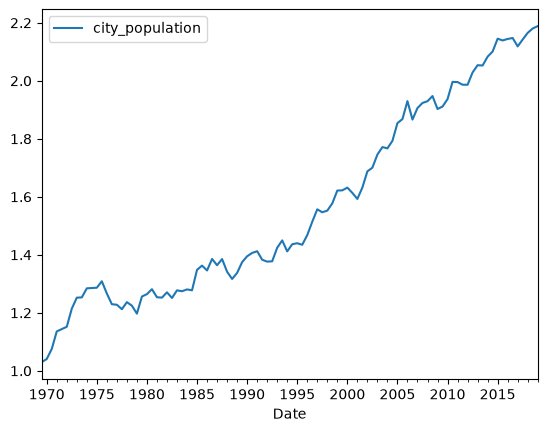

ADF Statistic: 0.16409185902167378
p-value: 0.9701741572469212


In [7]:
# Run the ADF test on the time series
result = adfuller(city['city_population'])

# Plot the time series
fig, ax = plt.subplots()
city.plot(ax=ax)
plt.show()

# Print the test statistic and the p-value
print('ADF Statistic:', result[0])
print('p-value:', result[1])

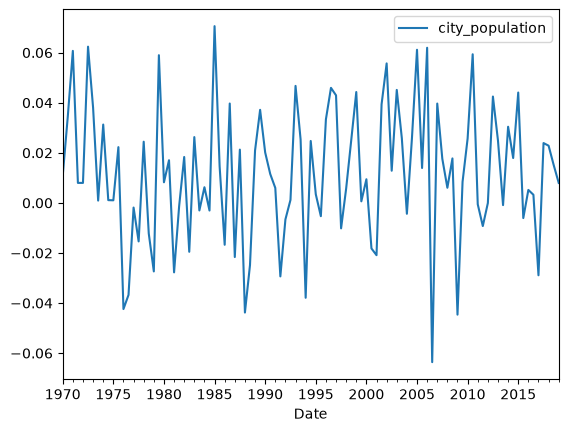

ADF Statistic: -10.008881137130233
p-value: 1.8006877207195796e-17


In [8]:
# Calculate the first difference of the time series
city_stationary = city.diff().dropna()

# Run ADF test on the differenced time series
result = adfuller(city_stationary['city_population'])

# Plot the differenced time series
fig, ax = plt.subplots()
city_stationary.plot(ax=ax)
plt.show()

# Print the test statistic and the p-value
print('ADF Statistic:', result[0])
print('p-value:', result[1])

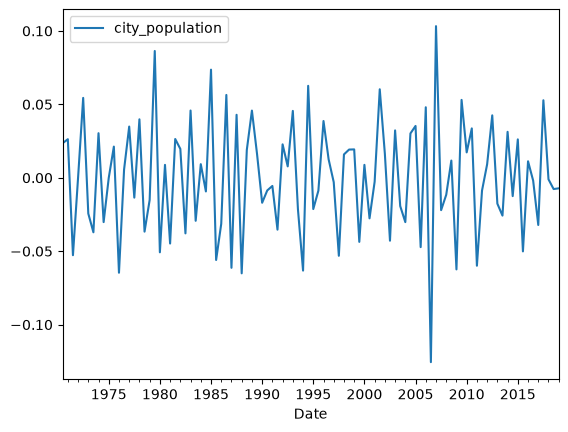

ADF Statistic: -5.560762131204935
p-value: 1.5437346090998995e-06


In [9]:
# Calculate the second difference of the time series
city_stationary = city.diff().diff().dropna()

# Run ADF test on the differenced time series
result = adfuller(city_stationary['city_population'])

# Plot the differenced time series
fig, ax = plt.subplots()
city_stationary.plot(ax=ax)
plt.show()

# Print the test statistic and the p-value
print('ADF Statistic:', result[0])
print('p-value:', result[1])

##########################################################################


# Otras transformaciones para lograr estacionariedad

La **diferenciación** suele ser la primera técnica para hacer estacionaria una serie, pero no siempre es la mejor opción.

En series financieras es muy común utilizar el **log-retorno**:

$$
r_t=\log\left(\frac{P_t}{P_{t-1}}\right)
$$

donde \(P_t\) es el precio en el instante \(t\).

## Transformaciones evaluadas

### 1. Primera diferencia

```python
amazon_diff = amazon.diff().dropna()
result_diff = adfuller(amazon_diff['close'])
```

Resultado:

```text
p-value = 2.33e-10
```

⇒ La serie es estacionaria.

---

### 2. Log-retornos

```python
amazon_log = np.log(
    amazon / amazon.shift(1)
).dropna()

result_log = adfuller(
    amazon_log['close']
)
```

Si el p-value también es menor a 0.05, la serie es estacionaria.

---

## Conclusión

Tanto la **primera diferencia** como los **log-retornos** suelen eliminar la no estacionariedad de los precios de las acciones. Sin embargo, en finanzas se prefieren los **log-retornos** porque:

- Representan cambios porcentuales.
- Son más fáciles de interpretar.
- Poseen mejores propiedades estadísticas para modelado.

In [10]:
amazon = pd.read_csv(
    'amazon_close.csv',
    parse_dates=['date'],
    index_col='date'
)

amazon = amazon.sort_index()

# Calculate the first difference and drop the nans
amazon_diff = amazon.diff()
amazon_diff = amazon_diff.dropna()

# Run test and print
result_diff = adfuller(amazon_diff['close'])
print(result_diff)

# Calculate log-return and drop nans
amazon_log = np.log(amazon/amazon.shift(1))
amazon_log = amazon_log.dropna()

# Run test and print
result_log = adfuller(amazon_log['close'])
print(result_log)

(np.float64(-7.201108938057444), np.float64(2.3642150138959623e-10), 23, 1234, {'1%': np.float64(-3.435660336370594), '5%': np.float64(-2.863885022214541), '10%': np.float64(-2.568018522153254)}, np.float64(10862.499714083922))
(np.float64(-34.8927194678206), 0.0, 0, 1257, {'1%': np.float64(-3.4355629707955395), '5%': np.float64(-2.863842063387667), '10%': np.float64(-2.567995644141416)}, np.float64(-6221.259222090162))


## Comparación: Primera Diferencia vs. Log-Retorno

Ambas transformaciones lograron hacer la serie de precios de Amazon **estacionaria**, ya que sus pruebas ADF produjeron:

```text
p-value < 0.05
```

Sin embargo, el **log-retorno** obtuvo un estadístico ADF más negativo.

### Interpretación

```text
Estadístico ADF más negativo
        ↓
Mayor evidencia contra la hipótesis de no estacionariedad
        ↓
Serie más claramente estacionaria
```

### Conclusión

Aunque la **primera diferencia** funciona, el **log-retorno** es una mejor transformación para esta serie porque genera una serie más estacionaria.

Además, en finanzas los log-retornos son preferidos porque:

- Representan cambios porcentuales.
- Son más fáciles de interpretar.
- Suelen tener mejores propiedades estadísticas para el modelado de series financieras.

##################################################################################

# Introducción a los modelos AR, MA y ARMA

## Modelo Autorregresivo (AR)

Un modelo **AR(p)** explica el valor actual de la serie usando sus valores pasados.

### AR(1)

$$
y_t = a_1 y_{t-1} + \varepsilon_t
$$

donde:

- \(a_1\): coeficiente autorregresivo.
- \(\varepsilon_t\): ruido blanco.

### AR(p)

$$
y_t = a_1y_{t-1}+a_2y_{t-2}+\cdots+a_py_{t-p}+\varepsilon_t
$$

- **p** = número de rezagos utilizados.

---

## Modelo de Media Móvil (MA)

Un modelo **MA(q)** explica el valor actual usando los errores (shocks) pasados.

### MA(1)

$$
y_t = \varepsilon_t + m_1\varepsilon_{t-1}
$$

donde:

- \(m_1\): coeficiente de media móvil.
- $$ \varepsilon_t $$: ruido blanco.

### MA(q)

$$
y_t=\varepsilon_t+m_1\varepsilon_{t-1}
+\cdots+m_q\varepsilon_{t-q}
$$

- **q** = número de rezagos de los errores.

---

## Modelo ARMA

Combina ambas ideas:

- Dependencia de los valores pasados (**AR**).
- Dependencia de los errores pasados (**MA**).

### ARMA(1,1)

$$
y_t=a_1y_{t-1}
+\varepsilon_t
+m_1\varepsilon_{t-1}
$$

### ARMA(p,q)

$$
y_t=
a_1y_{t-1}
+\cdots
+a_py_{t-p}
+
\varepsilon_t
+
m_1\varepsilon_{t-1}
+\cdots
+m_q\varepsilon_{t-q}
$$

---

# Simulación de datos ARMA

Con `statsmodels` se pueden generar series sintéticas:

```python
from statsmodels.tsa.arima_process import arma_generate_sample

ar = [1, -0.5]   # AR(1) con coeficiente 0.5
ma = [1, 0.2]    # MA(1) con coeficiente 0.2

y = arma_generate_sample(
    ar,
    ma,
    nsample=1000
)
```

**Importante:** en `statsmodels` los coeficientes AR se ingresan con el **signo contrario**.

---

# Ajuste de un modelo ARMA

```python
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(
    y,
    order=(1,0,1)
)

res = model.fit()
```

---

# Idea principal

```text
AR(p)     → usa valores pasados
MA(q)     → usa errores pasados
ARMA(p,q) → usa ambos
```

# Generación de datos ARMA simulados

La función `arma_generate_sample()` permite crear series de tiempo sintéticas a partir de coeficientes AR y MA.

## Convenciones de los coeficientes

Para un modelo **ARMA(p,q)**:

```python
ar_coefs = [1, -a1, -a2, ..., -ap]
ma_coefs = [1,  m1,  m2, ...,  mq]
```

**Importante:** los coeficientes AR se ingresan con el signo contrario.

---

## Ejemplos

### 1. MA(1) con coeficiente -0.7

```python
ar_coefs = [1]
ma_coefs = [1, -0.7]
```

Genera una serie que depende del error actual y del error del período anterior.

---

### 2. AR(2) con coeficientes 0.3 y 0.2

```python
ar_coefs = [1, -0.3, -0.2]
ma_coefs = [1]
```

La serie depende de los dos valores pasados:

$$
y_t = 0.3y_{t-1}+0.2y_{t-2}+\varepsilon_t
$$

---

### 3. Modelo ARMA(1,2)

```python
ar_coefs = [1, 0.2]
ma_coefs = [1, 0.3, 0.4]
```

Corresponde a:

$$
y_t=
-0.2y_{t-1}
+\varepsilon_t
+0.3\varepsilon_{t-1}
+0.4\varepsilon_{t-2}
$$

---

## Idea principal

```text
MA(1)     → depende de errores pasados.
AR(2)     → depende de valores pasados.
ARMA(1,2) → depende de ambos.
```

Las series simuladas son muy útiles para entender el comportamiento de los modelos antes de aplicarlos a datos reales.

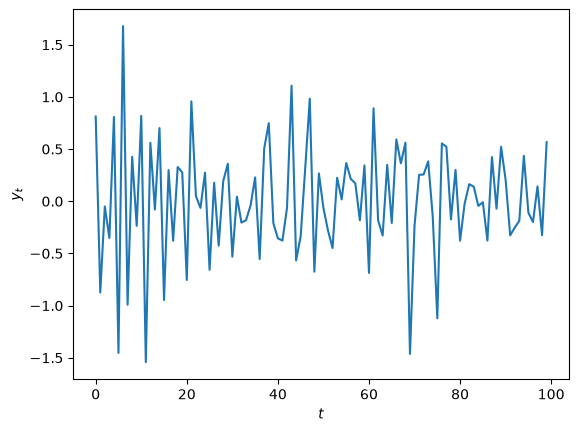

In [11]:
# Import data generation function and set random seed
from statsmodels.tsa.arima_process import arma_generate_sample
np.random.seed(1)

# Set coefficients
ar_coefs = [1]
ma_coefs = [1, -0.7]

# Generate data
y = arma_generate_sample(ar_coefs, ma_coefs, nsample=100, scale=0.5)

plt.plot(y)
plt.ylabel(r'$y_t$')
plt.xlabel(r'$t$')
plt.show()

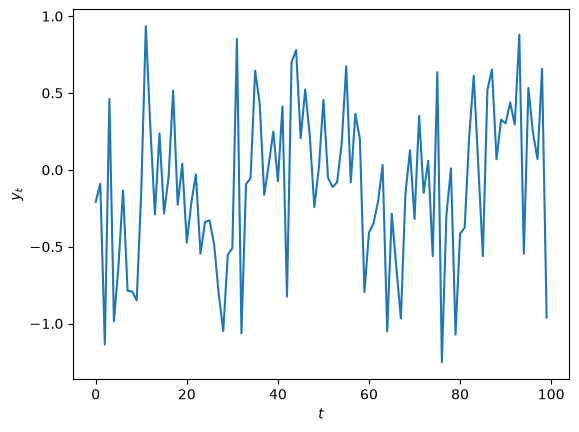

In [12]:
# Import data generation function and set random seed
from statsmodels.tsa.arima_process import arma_generate_sample
np.random.seed(2)

# Set coefficients
ar_coefs = [1, -0.3, -0.2]
ma_coefs = [1]

# Generate data
y = arma_generate_sample(ar_coefs, ma_coefs, nsample=100, scale=0.5)

plt.plot(y)
plt.ylabel(r'$y_t$')
plt.xlabel(r'$t$')
plt.show()

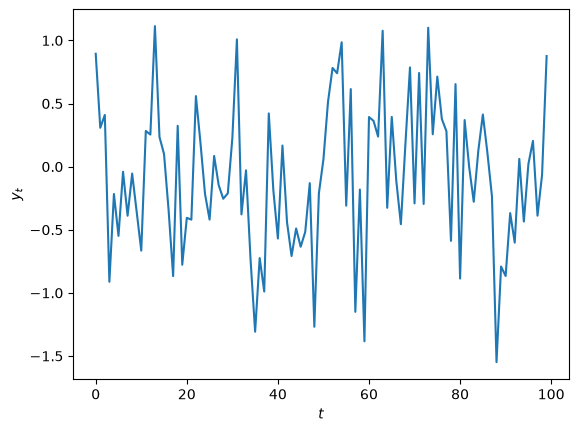

In [13]:
# Import data generation function and set random seed
from statsmodels.tsa.arima_process import arma_generate_sample
np.random.seed(3)

# Set coefficients
ar_coefs = [1, 0.2]
ma_coefs = [1, 0.3,0.4]

# Generate data
y = arma_generate_sample(ar_coefs, ma_coefs, nsample=100, scale=0.5)

plt.plot(y)
plt.ylabel(r'$y_t$')
plt.xlabel(r'$t$')
plt.show()

# Ajuste preliminar de un modelo ARMA(1,1)

En este ejercicio se realiza el proceso básico de **ajustar un modelo de series de tiempo**.

## Paso 1: Importar el modelo

```python
from statsmodels.tsa.arima.model import ARIMA
```

## Paso 2: Crear el modelo

```python
model = ARIMA(y, order=(1,0,1))
```

El orden `(1,0,1)` significa:

- **p = 1:** un término autorregresivo (AR).
- **d = 0:** no se diferencia la serie (ya es estacionaria).
- **q = 1:** un término de media móvil (MA).

Es decir, se está ajustando un:

```text
ARMA(1,1)
```

## Paso 3: Ajustar el modelo

```python
results = model.fit()
```

Este paso estima los parámetros del modelo a partir de los datos de la serie `y`.

---

## Objetivo

```text
Serie de tiempo
        ↓
Elegir (p,d,q)
        ↓
Crear el modelo
        ↓
Ajustar con .fit()
        ↓
Obtener parámetros y realizar pronósticos
```

El objeto `results` contiene toda la información del modelo estimado: coeficientes, AIC, BIC, residuos y métodos de predicción.

In [14]:
# Import the ARIMA model
from statsmodels.tsa.arima.model import ARIMA

# Instantiate the model
model = ARIMA(y, order=(1,0,1))

# Fit the model
results = model.fit()

################################################


# Ajuste de modelos de series de tiempo

## Crear un modelo

Se utiliza la clase:

```python
from statsmodels.tsa.arima.model import ARIMA
```

El orden del modelo es:

```python
(p, d, q)
```

donde:

- **p**: número de rezagos autorregresivos (AR).
- **d**: número de diferenciaciones.
- **q**: número de rezagos de media móvil (MA).

Si:

```text
d = 0
```

el modelo es un **ARMA(p,q)**.

---

## Casos particulares

- **AR(p):**

```python
order=(p,0,0)
```

- **MA(q):**

```python
order=(0,0,q)
```

- **ARMA(p,q):**

```python
order=(p,0,q)
```

---

## Ajustar el modelo

```python
model = ARIMA(data, order=(p,d,q))
results = model.fit()
```

---

## Resumen del ajuste

```python
print(results.summary())
```

El resumen muestra:

- Orden del modelo.
- Número de observaciones.
- Coeficientes AR y MA estimados.
- Errores estándar.
- Varianza de los errores (`sigma2`).
- Métricas como AIC y BIC.

---

# Modelos ARMAX

Los modelos **ARMAX** incorporan variables externas (**exógenas**) además de la propia serie temporal.

Por ejemplo:

```text
Productividad = función de:
- Productividad pasada (ARMA)
- Horas de sueño (variable exógena)
```

Se ajustan de la misma manera:

```python
model = ARIMA(
    y,
    exog=x,
    order=(p,d,q)
)
results = model.fit()
```

---

# Ejercicio: Ajustar modelos AR y MA

Para ajustar un **AR(2)**:

```python
model = ARIMA(
    sample['timeseries_1'],
    order=(2,0,0)
)

results = model.fit()

print(results.summary())
```

La idea es practicar el ajuste sobre datos simulados cuyos parámetros verdaderos son conocidos antes de pasar a datos reales.


###################################################


# Ajuste de un modelo ARMA(3,1) a la serie de terremotos

La serie `earthquake` ya se determinó como **estacionaria**, por lo que no es necesario diferenciarla (`d=0`).

Por ello, se puede ajustar directamente un modelo:

```text
ARMA(3,1)
```

que equivale a:

```python
order=(3,0,1)
```

donde:

- `p = 3` → se utilizan los últimos 3 rezagos de la serie (AR).
- `d = 0` → no se aplica diferenciación.
- `q = 1` → se utiliza un rezago del error (MA).

## Código

```python
# Crear el modelo
model = ARIMA(
    earthquake,
    order=(3,0,1)
)

# Ajustar el modelo
results = model.fit()

# Mostrar resumen
print(results.summary())
```

## Objetivo

El ajuste estima:

- Los coeficientes AR(1), AR(2) y AR(3).
- El coeficiente MA(1).
- La varianza del error (`sigma2`).
- Métricas de ajuste como AIC y BIC.

## Flujo del proceso

```text
Serie estacionaria
        ↓
Seleccionar orden (3,0,1)
        ↓
Ajustar modelo ARMA(3,1)
        ↓
Analizar parámetros y calidad del ajuste
        ↓
Realizar pronósticos
```

La llamada:

```python
print(results.summary())
```

permite verificar si los coeficientes son significativos y evaluar si el modelo es adecuado para la serie de terremotos.

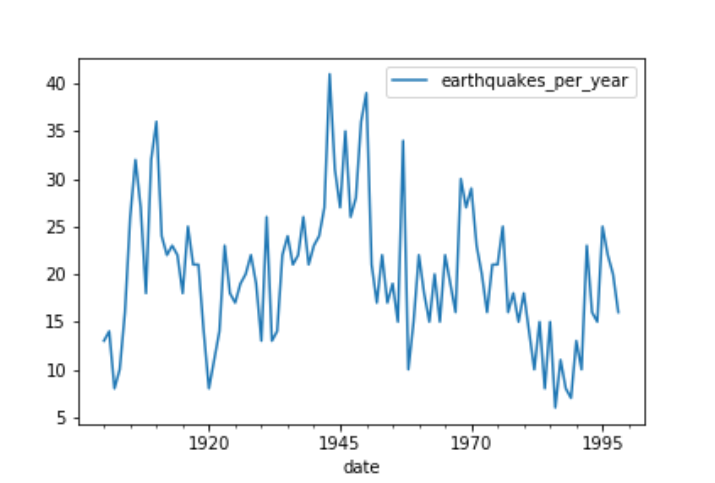

In [15]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(
    earthquake['earthquakes_per_year'],
    order=(3,0,1)
)

results = model.fit()

print(results.summary())

                                SARIMAX Results                                 
Dep. Variable:     earthquakes_per_year   No. Observations:                   99
Model:                   ARIMA(3, 0, 1)   Log Likelihood                -315.673
Date:                  Wed, 15 Jul 2026   AIC                            643.345
Time:                          12:35:31   BIC                            658.916
Sample:                      01-01-1900   HQIC                           649.645
                           - 01-01-1998                                         
Covariance Type:                    opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         19.6453      2.233      8.798      0.000      15.269      24.022
ar.L1          0.5795      0.645      0.899      0.369      -0.684       1.843
ar.L2          0.0251      0.308    

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)


###################################################################

# Ajuste de un modelo ARMAX(2,1)

En este ejercicio se modelan los **tiempos de espera en urgencias** (`wait_times_hrs`) incorporando una variable externa: el **número de enfermeras en turno** (`nurse_count`).

## Modelo utilizado

Se ajusta un modelo:

```text
ARMAX(2,1)
```

equivalente a:

```python
order=(2,0,1)
```

donde:

- **p = 2** → se utilizan dos rezagos de los tiempos de espera.
- **d = 0** → la serie ya es estacionaria.
- **q = 1** → se utiliza un rezago del error.
- **exog = nurse_count** → variable externa que puede influir en los tiempos de espera.

## Código

```python
model = ARIMA(
    hospital['wait_times_hrs'],
    order=(2,0,1),
    exog=hospital['nurse_count']
)

results = model.fit()

print(results.summary())
```

## Objetivo

Determinar si el número de enfermeras tiene un efecto significativo sobre los tiempos de espera.

- Coeficiente de `nurse_count` **negativo**:
  
  ```text
  Más enfermeras → Menores tiempos de espera
  ```

- Coeficiente **positivo**:

  ```text
  Más enfermeras → Mayores tiempos de espera
  ```

## Idea principal

```text
Tiempo de espera actual
        ↓
Depende de:
- Tiempos de espera pasados (AR)
- Errores pasados (MA)
- Número de enfermeras (variable exógena)
```

El modelo ARMAX permite no solo hacer pronósticos, sino también evaluar cómo cambios en variables externas pueden afectar la serie de interés.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

# --------------------------
# Índice horario (1 semana)
# --------------------------
n = 168

dates = pd.date_range(
    start='2019-03-04 00:00:00',
    periods=n,
    freq='h'
)

# --------------------------
# Variable exógena
# Número de enfermeras
# --------------------------
nurse_count = np.random.randint(2, 8, n)

# --------------------------
# Parámetros del ARIMAX(2,0,1)
# --------------------------
const = 2.5
beta = -0.18

phi1 = 0.5
phi2 = -0.2

theta1 = 0.4

# --------------------------
# Generar errores
# --------------------------
eps = np.random.normal(
    loc=0,
    scale=0.15,
    size=n
)

# --------------------------
# Generar serie ARIMAX
# --------------------------
wait_times = np.zeros(n)

# condiciones iniciales
wait_times[0] = 1.5
wait_times[1] = 1.7

for t in range(2, n):

    wait_times[t] = (
        const
        + beta * nurse_count[t]
        + phi1 * wait_times[t-1]
        + phi2 * wait_times[t-2]
        + theta1 * eps[t-1]
        + eps[t]
    )

# evitar tiempos negativos
wait_times = np.clip(wait_times, 0.1, None)

# --------------------------
# Construir DataFrame
# --------------------------
hospital = pd.DataFrame(
    {
        'wait_times_hrs': np.round(wait_times, 3),
        'nurse_count': nurse_count.astype(float)
    },
    index=dates
)

# Dar nombre al índice
hospital.index.name = 'Date'
hospital.head()


,wait_times_hrs,nurse_count
Date,,
2019-03-04 00:00:00,1.500,5.0
2019-03-04 01:00:00,1.700,6.0
2019-03-04 02:00:00,2.375,4.0
2019-03-04 03:00:00,2.419,6.0
2019-03-04 04:00:00,2.107,6.0


In [17]:
hospital.to_csv('hospital_wait_times.csv')

In [18]:
hospital = pd.read_csv('hospital_wait_times.csv', index_col='Date', parse_dates=True)

In [19]:
# Instantiate the model
model = ARIMA(hospital['wait_times_hrs'], order=(2,0,1), 
             exog=hospital['nurse_count'])

# Fit the model
results = model.fit()

# Print model fit summary
print(results.summary())

                               SARIMAX Results                                
Dep. Variable:         wait_times_hrs   No. Observations:                  168
Model:                 ARIMA(2, 0, 1)   Log Likelihood                  27.454
Date:                Wed, 15 Jul 2026   AIC                            -42.908
Time:                        12:35:32   BIC                            -24.164
Sample:                    03-04-2019   HQIC                           -35.301
                         - 03-10-2019                                         
Covariance Type:                  opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           2.9525      0.045     66.230      0.000       2.865       3.040
nurse_count    -0.1193      0.008    -15.170      0.000      -0.135      -0.104
ar.L1           0.3409      0.142      2.400    

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


# Conclusiones del modelo ARIMAX(2,0,1)

## Efecto de la variable exógena (`nurse_count`)

El coeficiente estimado es:

```text
nurse_count = -0.1193
p-value < 0.001
```

### Interpretación

Por cada enfermera adicional en turno:

```text
el tiempo de espera disminuye en aproximadamente 0.12 horas
```

es decir:

```text
0.12 × 60 ≈ 7.2 minutos.
```

## Significancia estadística

El p-value es prácticamente cero:

```text
P>|z| = 0.000
```

por lo que existe evidencia estadística muy fuerte de que el número de enfermeras influye en los tiempos de espera.

## Interpretación de negocio

```text
Más enfermeras → Menores tiempos de espera.
```

El efecto además es cuantificable:

| Enfermeras adicionales | Reducción esperada |
|------------------------|-------------------|
| +1 enfermera | ~7 minutos |
| +2 enfermeras | ~14 minutos |
| +3 enfermeras | ~21 minutos |

## Conclusión principal

La variable exógena `nurse_count` es un **driver importante** de la serie:

```text
wait_times_hrs
      ↓
depende significativamente de
nurse_count
```

Por tanto, este modelo no solo sirve para pronosticar, sino también para realizar análisis de escenarios:

- ¿Qué pasa si agrego una enfermera?
- ¿Cuántas enfermeras necesito para mantener la espera por debajo de cierto umbral?

La inclusión de la variable exógena aporta capacidad **predictiva y explicativa**, permitiendo convertir el modelo en una herramienta de apoyo para la planificación operativa del hospital.

#####################################################


# Forecasting con modelos ARIMA/ARMA

## Tipos de predicción

### 1. One-step-ahead prediction
Predice **un paso hacia adelante** utilizando los valores reales observados de la serie.

- Permite evaluar qué tan bueno es el modelo dentro de la muestra (*in-sample*).
- La incertidumbre proviene de los términos de error (shocks).

### 2. Dynamic prediction
Predice varios pasos hacia adelante utilizando las propias predicciones del modelo como entradas futuras.

- La incertidumbre crece rápidamente.
- Los errores se van acumulando.

### 3. Out-of-sample forecast
Pronostica valores futuros que aún no se han observado.

---

# Generar predicciones de un paso adelante

```python
one_step_forecast = results.get_prediction(start=-30)
```

Genera predicciones para los últimos 30 períodos de la serie.

---

# Obtener la predicción media

```python
mean_forecast = one_step_forecast.predicted_mean
```

Contiene el valor esperado o mejor estimación del pronóstico.

---

# Obtener intervalos de confianza

```python
confidence_intervals = one_step_forecast.conf_int()
```

Extrae los límites inferior y superior de las predicciones:

```python
lower_limits = confidence_intervals['lower close']
upper_limits = confidence_intervals['upper close']
```

Estos intervalos representan la incertidumbre del pronóstico.

---

# Código completo

```python
one_step_forecast = results.get_prediction(start=-30)

mean_forecast = one_step_forecast.predicted_mean

confidence_intervals = one_step_forecast.conf_int()

lower_limits = confidence_intervals['lower close']
upper_limits = confidence_intervals['upper close']

print(mean_forecast)
```

---

# Idea principal

```text
Valor observado(t-1)
          ↓
      Modelo ARIMA
          ↓
 Predicción en t
          ↓
 Intervalo de confianza
```

Las predicciones de un paso adelante son la forma más común de evaluar el desempeño de un modelo antes de utilizarlo para realizar pronósticos futuros.

# Graficar predicciones de un paso adelante

Se comparan las predicciones del modelo con los valores reales de la acción de Amazon durante los últimos 30 días.

## Pasos

1. Graficar la serie observada (`amazon`).
2. Graficar la predicción media (`mean_forecast`).
3. Graficar el intervalo de confianza usando un área sombreada entre los límites inferior y superior.

## Código

```python
plt.plot(amazon.index, amazon, label='observed')

plt.plot(
    mean_forecast.index,
    mean_forecast,
    color='r',
    label='forecast'
)

plt.fill_between(
    lower_limits.index,
    lower_limits,
    upper_limits,
    color='pink'
)

plt.xlabel('Date')
plt.ylabel('Amazon Stock Price - Close USD')
plt.legend()
plt.show()
```

## Interpretación

- **Línea azul:** precios reales observados.
- **Línea roja:** predicciones del modelo.
- **Área rosada:** intervalo de confianza de las predicciones.

Mientras más cerca esté la línea roja de la azul y más estrecho sea el intervalo de confianza, mejor es el desempeño predictivo del modelo.

In [20]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(amazon['close'], order=(1,1,1))
results = model.fit()

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


In [21]:
one_step_forecast = results.get_prediction(
    start=amazon.index[-30]
)

mean_forecast = one_step_forecast.predicted_mean

confidence_intervals = one_step_forecast.conf_int()

lower_limits = confidence_intervals.iloc[:,0]
upper_limits = confidence_intervals.iloc[:,1]

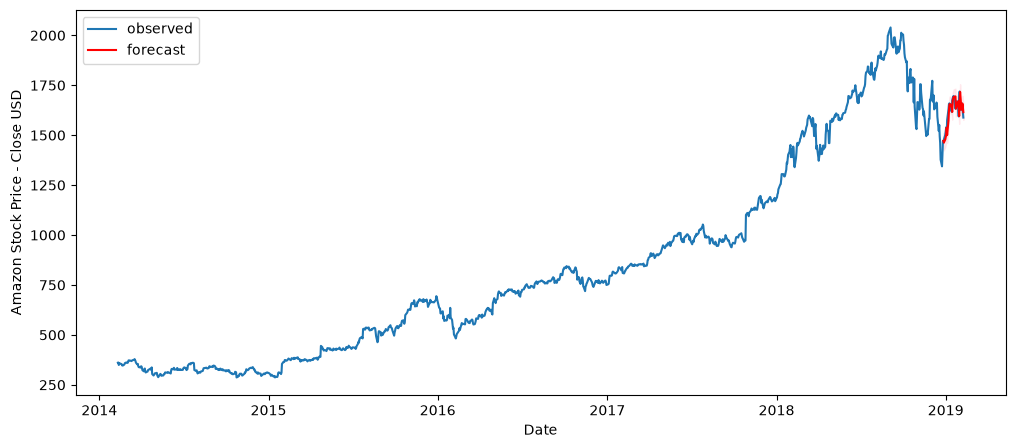

In [22]:
plt.figure(figsize=(12,5))

plt.plot(
    amazon.index,
    amazon['close'],
    label='observed'
)

plt.plot(
    mean_forecast.index,
    mean_forecast,
    color='r',
    label='forecast'
)

plt.fill_between(
    lower_limits.index,
    lower_limits,
    upper_limits,
    color='pink',
    alpha=0.3
)

plt.xlabel('Date')
plt.ylabel('Amazon Stock Price - Close USD')
plt.legend()
plt.show()

In [23]:
# Generate predictions
dynamic_forecast = results.get_prediction(start=-30, dynamic=True)

# Extract prediction mean
mean_forecast = dynamic_forecast.predicted_mean

# Get confidence intervals of predictions
confidence_intervals = dynamic_forecast.conf_int()

# Select lower and upper confidence limits
lower_limits = confidence_intervals.loc[:,'lower close']
upper_limits = confidence_intervals.loc[:,'upper close']

# Print best estimate predictions
print(mean_forecast)

date
2018-12-27    1471.921849
2018-12-28    1472.746009
2018-12-31    1473.410725
2019-01-02    1473.946843
2019-01-03    1474.379242
2019-01-04    1474.727988
2019-01-07    1475.009265
2019-01-08    1475.236125
2019-01-09    1475.419096
2019-01-10    1475.566669
2019-01-11    1475.685693
2019-01-14    1475.781690
2019-01-15    1475.859114
2019-01-16    1475.921561
2019-01-17    1475.971926
2019-01-18    1476.012547
2019-01-22    1476.045310
2019-01-23    1476.071734
2019-01-24    1476.093046
2019-01-25    1476.110235
2019-01-28    1476.124099
2019-01-29    1476.135280
2019-01-30    1476.144299
2019-01-31    1476.151572
2019-02-01    1476.157439
2019-02-04    1476.162170
2019-02-05    1476.165986
2019-02-06    1476.169064
2019-02-07    1476.171547
2019-02-08    1476.173549
Name: predicted_mean, dtype: float64


## Dynamic Forecasts (Pronósticos dinámicos)

- En un **one-step-ahead forecast**, cada predicción usa el valor real observado del período anterior.
- En un **dynamic forecast**, después del primer paso, el modelo utiliza sus **propias predicciones** para estimar los siguientes períodos.

### Código

```python
dynamic_forecast = results.get_prediction(
    start=-30,
    dynamic=True
)

mean_forecast = dynamic_forecast.predicted_mean
confidence_intervals = dynamic_forecast.conf_int()
```

### ¿Qué ocurre?

1. Se generan predicciones para los últimos 30 períodos.
2. Cada nueva predicción depende de las predicciones anteriores del modelo.
3. La incertidumbre aumenta con el horizonte de predicción.

### Interpretación de los resultados

- Las predicciones convergen gradualmente hacia un valor alrededor de **1623 USD**.
- Esto es típico de modelos ARIMA estacionarios, que tienden a regresar hacia su media de largo plazo.
- A medida que se avanza en el tiempo, el modelo pierde precisión porque los errores (shocks) se acumulan.

### Idea clave

> Cuanto más lejos se pronostica en el futuro, mayor es la incertidumbre del pronóstico.

Por esta razón:

- Los **one-step forecasts** suelen ser más precisos.
- Los **dynamic forecasts** son más útiles para analizar tendencias generales que para predecir valores exactos de largo plazo.

## Plotting Dynamic Forecasts

### Objetivo
Visualizar las predicciones dinámicas del modelo ARIMA y su incertidumbre.

### ¿Qué se grafica?

1. **Serie observada (Amazon):**
   ```python
   plt.plot(amazon.index, amazon, label='observed')
   ```

2. **Pronóstico dinámico:**
   ```python
   plt.plot(mean_forecast.index, mean_forecast,
            color='r', label='forecast')
   ```

3. **Intervalos de confianza:**
   ```python
   plt.fill_between(
       lower_limits.index,
       lower_limits,
       upper_limits,
       color='pink'
   )
   ```

---

### Interpretación

- La línea **azul** corresponde a los precios reales de Amazon.
- La línea **roja** muestra las predicciones del modelo.
- La zona **rosada** representa el intervalo de confianza (generalmente al 95%).

### Idea clave

En un **pronóstico dinámico**, el modelo utiliza sus propias predicciones para estimar los siguientes períodos:

```text
Predicción t+1 → Predicción t+2 → Predicción t+3 → ...
```

Por ello:

- La incertidumbre aumenta con el horizonte de predicción.
- Los intervalos de confianza se ensanchan a medida que avanzamos en el tiempo.
- Las predicciones de largo plazo suelen ser menos precisas que las de un solo paso adelante (*one-step-ahead*).

> Cuanto más lejos se pronostica en el futuro, mayor es la incertidumbre y menor la precisión del modelo.

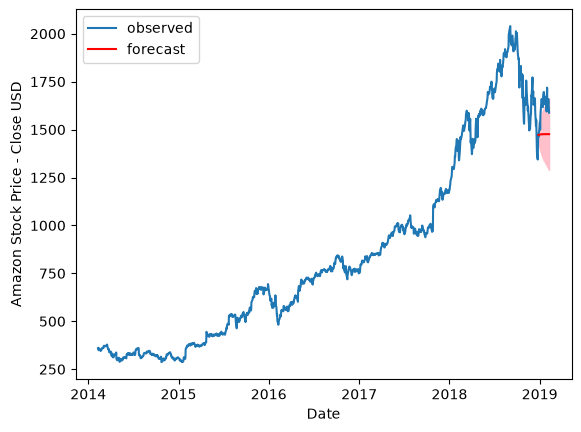

In [24]:
# plot the amazon data
plt.plot(amazon.index,amazon, label='observed')

# plot your mean forecast
plt.plot(mean_forecast.index, mean_forecast, color='r', label='forecast')

# shade the area between your confidence limits
plt.fill_between(lower_limits.index, lower_limits, 
         upper_limits, color='pink')

# set labels, legends and show plot
plt.xlabel('Date')
plt.ylabel('Amazon Stock Price - Close USD')
plt.legend()
plt.show()

####################################################################################################


## Introducción a los modelos ARIMA

### Problema
Los modelos **ARMA** solo pueden aplicarse a series **estacionarias**.

Si la serie tiene tendencia o es no estacionaria:

1. Se debe **diferenciar** la serie hasta volverla estacionaria.
2. Se ajusta un modelo ARMA sobre la serie diferenciada.
3. Se transforman nuevamente las predicciones a la escala original.

---

## Reconstrucción de la serie original

Si el modelo predice las diferencias:

```python
Δŷt
```

Para recuperar la serie original se utiliza la suma acumulada:

```python
ŷ = último_valor + np.cumsum(Δŷ)
```

---

## El modelo ARIMA

ARIMA automatiza todo este proceso:

- **AR (p):** componente autorregresivo.
- **I (d):** número de diferenciaciones.
- **MA (q):** componente de medias móviles.

```python
ARIMA(p, d, q)
```

donde:

- `p` = orden AR.
- `d` = número de diferencias necesarias para estacionarizar la serie.
- `q` = orden MA.

---

## Ejemplo

Si la serie necesita:

- 1 diferencia para ser estacionaria.
- Un modelo ARMA(2,1).

Entonces el modelo es:

```python
ARIMA(2,1,1)
```

```python
model = ARIMA(serie, order=(2,1,1))
results = model.fit()
forecast = results.get_forecast(steps=30)
```

---

## Idea clave

> Diferenciar solo hasta que la serie sea estacionaria, ni más ni menos.

El número de diferencias `d` se determina previamente mediante:

- Gráficos de la serie.
- Prueba de Dickey-Fuller (ADF).

Una vez elegido `d`, ARIMA se encarga automáticamente de:

1. Diferenciar la serie.
2. Ajustar el modelo.
3. Integrar las predicciones a la escala original.
4. Generar los pronósticos finales.

In [25]:
# Take the first difference of the data
amazon_diff = amazon.diff().dropna()

# Create ARMA(2,2) model
arma = ARIMA(amazon_diff,order=(2,0,2))

# Fit model
arma_results = arma.fit()

# Print fit summary
print(arma_results.summary())

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  close   No. Observations:                 1258
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -5532.371
Date:                Wed, 15 Jul 2026   AIC                          11076.743
Time:                        12:35:32   BIC                          11107.566
Sample:                             0   HQIC                         11088.327
                               - 1258                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9884      0.494      2.000      0.046       0.020       1.957
ar.L1         -0.1541      0.073     -2.119      0.034      -0.297      -0.012
ar.L2          0.7944      0.072     11.087      0.0

In [26]:
# Make arma forecast of next 10 differences
arma_diff_forecast = arma_results.get_forecast(steps=10).predicted_mean

# Integrate the difference forecast
arma_int_forecast = np.cumsum(arma_diff_forecast)

# Make absolute value forecast
arma_value_forecast = arma_int_forecast + amazon.iloc[-1,0]

# Print forecast
print(arma_value_forecast)

1258    1592.065206
1259    1594.214102
1260    1597.293268
1261    1598.881471
1262    1601.438453
1263    1602.661676
1264    1604.860049
1265    1605.848571
1266    1607.798212
1267    1608.638602
Name: predicted_mean, dtype: float64


c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


### Idea clave

Cuando una serie no es estacionaria y se diferencia para poder modelarla con un ARMA, el modelo ya no pronostica los valores originales, sino los **cambios entre períodos**. Por ello, una vez obtenidos los pronósticos de las diferencias, es necesario **acumular esos cambios y sumarlos al último valor observado** para reconstruir el pronóstico en la escala original de la serie.

In [27]:
# Create ARIMA(2,1,2) model
arima = ARIMA(amazon, order=(2,1,2))

# Fit ARIMA model
arima_results = arima.fit()

# Make ARIMA forecast of next 10 values
arima_value_forecast = arima_results.get_forecast(steps=10).predicted_mean

# Print forecast
print(arima_value_forecast)

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


1259    1594.860945
1260    1602.040981
1261    1603.246221
1262    1597.529057
1263    1590.232323
1264    1588.000579
1265    1592.732721
1266    1599.976772
1267    1603.113458
1268    1599.401513
Name: predicted_mean, dtype: float64


c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


### Idea clave

El modelo **ARIMA** automatiza todo el proceso de trabajar con series no estacionarias. Internamente, el modelo realiza la diferenciación necesaria (`d=1` en este caso), ajusta un modelo ARMA sobre la serie transformada y luego integra nuevamente las predicciones para devolver los pronósticos directamente en la **escala original** de la serie. Por ello, a diferencia del enfoque manual con ARMA, no es necesario calcular las diferencias ni reconstruir la serie mediante sumas acumuladas.

# Ejercicio: Selección del parámetro de diferenciación en un modelo ARIMA

Se está analizando una serie temporal y se aplicó la prueba de Dickey-Fuller Aumentada (ADF) después de diferentes grados de diferenciación.

Los resultados obtenidos fueron:

| Orden de diferenciación (d) | Estadístico ADF | p-value |
|-----------------------------|----------------|----------|
| 0                           | 2.198          | 0.999    |
| 1                           | -2.598         | 0.093    |
| 2                           | -14.448        | 0.000    |
| 3                           | -17.147        | 0.000    |

## Pregunta

¿Cuál de los siguientes modelos ARIMA debería ajustarse a esta serie temporal?

- [ ] ARIMA(p,0,q)
- [ ] ARIMA(p,1,q)
- [X] ARIMA(p,2,q)
- [ ] ARIMA(p,3,q)

---

## Solución

El objetivo es diferenciar la serie **solo hasta que se vuelva estacionaria**.

Analizando los resultados:

- **d = 0:** p-value = 0.999 > 0.05 → la serie no es estacionaria.
- **d = 1:** p-value = 0.093 > 0.05 → la serie sigue siendo no estacionaria.
- **d = 2:** p-value = 0.000 < 0.05 → se rechaza la hipótesis nula y la serie se considera estacionaria.
- **d = 3:** también es estacionaria, pero estaría **sobrediferenciada**.

Por lo tanto, el menor orden de diferenciación que logra la estacionariedad es:

```text
d = 2
```

y el modelo adecuado es:

```text
ARIMA(p,2,q)
```

---

## Idea clave

> En un modelo ARIMA, el parámetro `d` debe ser el **menor número de diferenciaciones necesarias para hacer estacionaria la serie**. Diferenciar más veces de las necesarias puede eliminar información útil y deteriorar el desempeño del modelo.


#############################################


# ACF y PACF para seleccionar modelos ARIMA

## ¿Por qué son importantes?

La elección de los parámetros `(p, d, q)` de un modelo ARIMA tiene un gran impacto en la calidad de los pronósticos. Dos herramientas fundamentales para identificar el orden del modelo son:

- **ACF (Autocorrelation Function)**: mide la correlación de la serie consigo misma en diferentes rezagos (lags).
- **PACF (Partial Autocorrelation Function)**: mide la correlación en un rezago específico eliminando el efecto de los rezagos anteriores.

---

## Interpretación de los gráficos

### Modelo AR(p)
- La **ACF decae gradualmente** (*tails off*).
- La **PACF se corta** después del rezago `p`.

```text
ACF  → decae
PACF → corte en p
```

---

### Modelo MA(q)
- La **ACF se corta** después del rezago `q`.
- La **PACF decae gradualmente**.

```text
ACF  → corte en q
PACF → decae
```

---

### Modelo ARMA(p,q)
- Tanto la **ACF** como la **PACF** decaen gradualmente.

```text
ACF  → decae
PACF → decae
```

En este caso, los valores de `p` y `q` no se pueden determinar directamente desde los gráficos.

---

## Señales de problemas de estacionariedad

- **ACF alta y decayendo muy lentamente**:
  
  ➜ La serie probablemente **no es estacionaria** y necesita más diferenciación.

- **Autocorrelación muy negativa en el lag 1**:
  
  ➜ La serie probablemente está **sobrediferenciada**.

---

## Implementación en Python

```python
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2,1)

plot_acf(series, lags=20, zero=False, ax=axes[0])
plot_pacf(series, lags=20, zero=False, ax=axes[1])

plt.show()
```

---

## Idea clave

> La ACF y la PACF son herramientas visuales que ayudan a identificar los órdenes `p` y `q` de un modelo ARIMA, siempre y cuando la serie ya haya sido transformada a una forma estacionaria.

# ¿AR o MA? Uso de la ACF y PACF

Cuando analizamos una serie temporal, las gráficas de **ACF** y **PACF** nos ayudan a decidir si el modelo adecuado es **AR**, **MA** o **ARMA**.

## Regla general

| Modelo | ACF | PACF |
|---------|-----|-------|
| **AR(p)** | Decae gradualmente (*tails off*) | Se corta en el lag `p` |
| **MA(q)** | Se corta en el lag `q` | Decae gradualmente (*tails off*) |
| **ARMA(p,q)** | Decae gradualmente | Decae gradualmente |

---

## ¿Qué significa "cuts off"?

Significa que después de cierto lag, las autocorrelaciones dejan de ser significativas y permanecen dentro de las bandas de confianza.

Ejemplo:

```text
Lag:    1   2   3   4   5
PACF: 0.6 0.3 0.0 0.0 0.0
```

La PACF se corta en el lag 2 → posible **AR(2)**.

---

## ¿Qué significa "tails off"?

Significa que las autocorrelaciones van disminuyendo poco a poco y no desaparecen de manera abrupta.

Ejemplo:

```text
Lag:    1    2    3    4    5
ACF: 0.7  0.5  0.3  0.2  0.1
```

La ACF decae gradualmente.

---

# Interpretación rápida

### Caso 1: AR(p)

```text
ACF   : ↓ ↓ ↓ ↓
PACF  : | | 0 0 0
```

➡️ La PACF determina el valor de `p`.

---

### Caso 2: MA(q)

```text
ACF   : | | 0 0 0
PACF  : ↓ ↓ ↓ ↓
```

➡️ La ACF determina el valor de `q`.

---

### Caso 3: ARMA(p,q)

```text
ACF   : ↓ ↓ ↓ ↓
PACF  : ↓ ↓ ↓ ↓
```

➡️ No se pueden identificar directamente `p` y `q`; normalmente se prueban varios modelos y se comparan con métricas como AIC o BIC.

---

# Idea clave

> La **PACF** sirve principalmente para identificar el orden de un modelo **AR**, mientras que la **ACF** sirve principalmente para identificar el orden de un modelo **MA**.

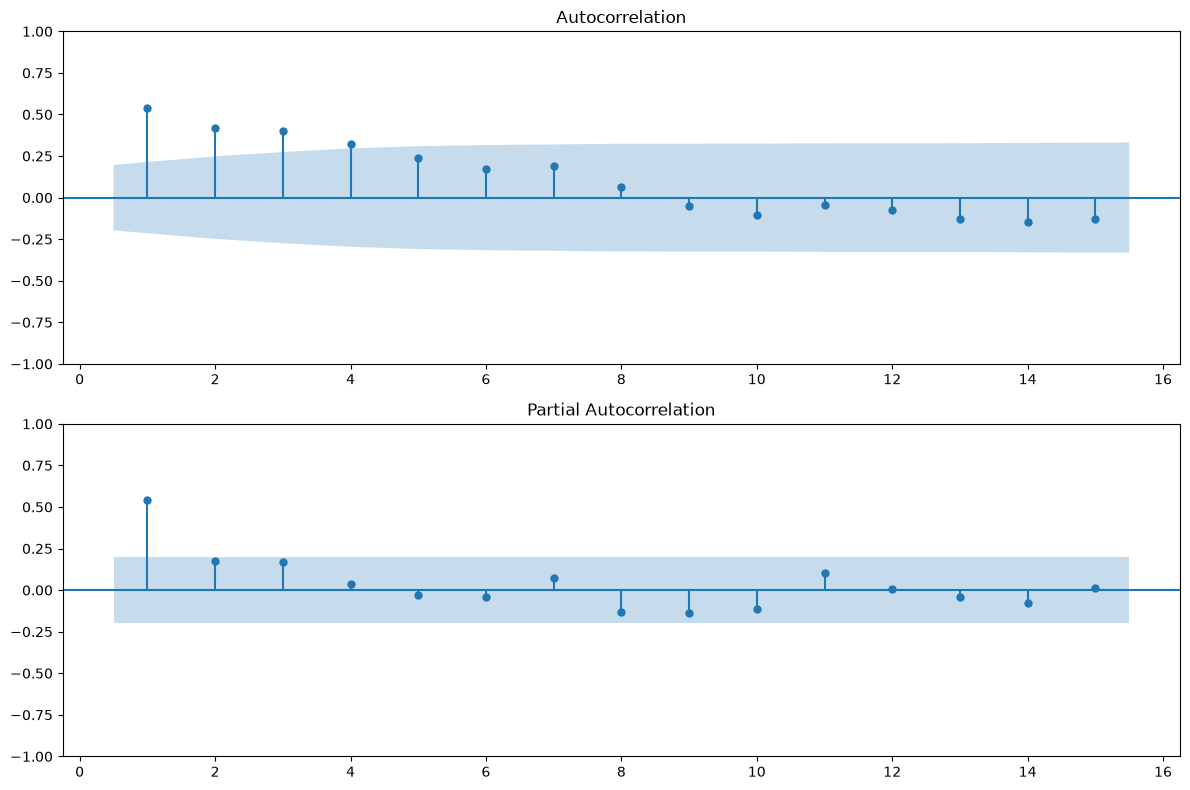

In [28]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(12, 8)
)

plot_acf(
    earthquake['earthquakes_per_year'],
    lags=15,
    zero=False,
    ax=ax1
)

plot_pacf(
    earthquake['earthquakes_per_year'],
    lags=15,
    zero=False,
    ax=ax2
)

plt.tight_layout()
plt.show()

### Idea clave

La **ACF** muestra un decaimiento gradual, mientras que la **PACF** presenta un pico significativo en el rezago 1 y luego se vuelve prácticamente insignificante. Este patrón es característico de un modelo **AR(1)**.

> **Regla práctica:** si la ACF decae y la PACF se corta después del lag `p`, la serie puede modelarse como un **AR(p)**. En este caso, la evidencia apunta a un **AR(1)** para la serie de terremotos.

In [29]:
earthquake = earthquake.drop(columns='Year')

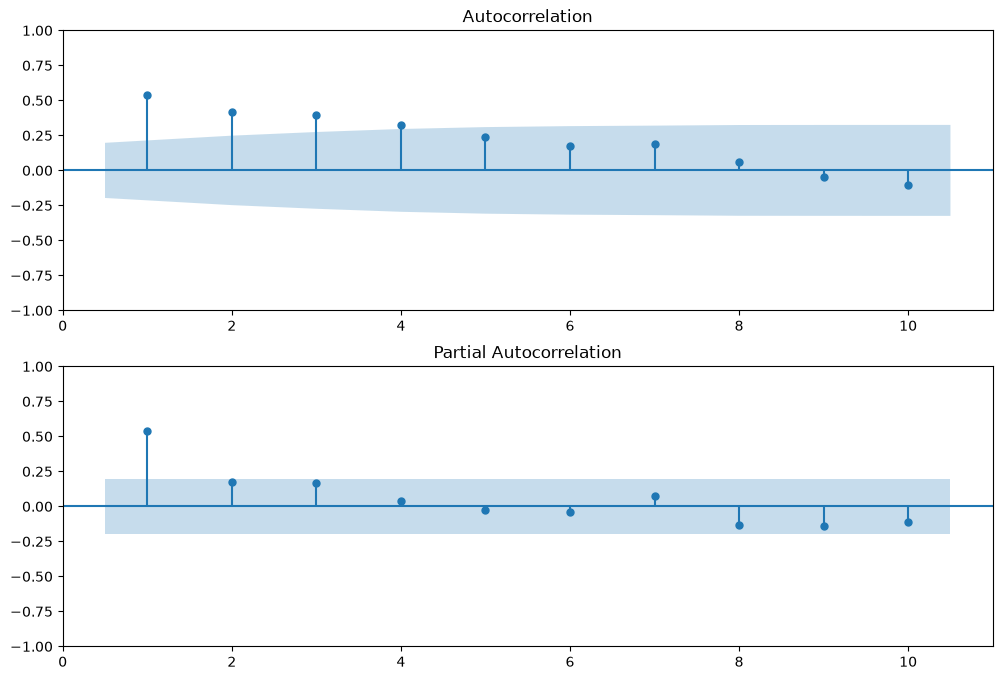

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)


In [30]:
# Create figure
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(12,8))

# Plot ACF and PACF
plot_acf(earthquake, lags=10, zero=False, ax=ax1)
plot_pacf(earthquake, lags=10, zero=False, ax=ax2)

# Show plot
plt.show()

# Instantiate model
model = ARIMA(earthquake, order = (1,0,0))

# Train model
results = model.fit()

#########################################################

# AIC y BIC para seleccionar modelos ARIMA/ARMA

## Idea principal
Cuando la **ACF y PACF no permiten identificar claramente** los órdenes `p` y `q`, se prueban varios modelos y se comparan usando **AIC** y **BIC**.

---

## AIC (Akaike Information Criterion)

- Mide la calidad del ajuste del modelo.
- Penaliza modelos con demasiados parámetros para evitar **overfitting**.
- **Menor AIC = mejor capacidad predictiva.**

---

## BIC (Bayesian Information Criterion)

- Similar al AIC, pero penaliza más fuertemente la complejidad del modelo.
- Tiende a elegir modelos más simples.
- **Menor BIC = mejor modelo explicativo.**

---

## Regla práctica

- **Objetivo predictivo → usar AIC.**
- **Objetivo explicativo o parsimonia → usar BIC.**

---

## Búsqueda de órdenes (Grid Search)

Se prueban múltiples combinaciones:

```python
for p in range(3):
    for q in range(3):
        model = ARIMA(df, order=(p,0,q))
        results = model.fit()
```

y se almacenan:

- `p`
- `q`
- `AIC`
- `BIC`

Luego se ordenan:

```python
order_df.sort_values('AIC')
order_df.sort_values('BIC')
```

---

## Cuando algunos modelos fallan

Algunas combinaciones `(p,q)` producen errores porque generan modelos:

- no estacionarios,
- no invertibles,
- o numéricamente inestables.

Por ello, se utiliza:

```python
try:
    ...
except:
    ...
```

para ignorar esos modelos y continuar la búsqueda.

---

## Idea clave

> **ACF/PACF sugieren candidatos; AIC y BIC ayudan a elegir el mejor modelo entre varias alternativas.**

In [31]:
import numpy as np
import pandas as pd

# Semilla para reproducibilidad
np.random.seed(42)

# Crear fechas diarias
dates = pd.date_range(
    start='2013-01-01',
    end='2014-05-15',
    freq='D'
)

# Generar una serie AR(1) simulada
n = len(dates)
y = np.zeros(n)

phi = 0.7
eps = np.random.normal(0, 1, n)

for t in range(1, n):
    y[t] = phi * y[t-1] + eps[t]

# Crear DataFrame
df = pd.DataFrame(
    {'y': y},
    index=dates
)

# Dar nombre al índice
df.index.name = 'date'

print(df.head())
print('...')
print(df.tail())

                   y
date                
2013-01-01  0.000000
2013-01-02 -0.138264
2013-01-03  0.550904
2013-01-04  1.908662
2013-01-05  1.101910
...
                   y
date                
2014-05-11  1.655225
2014-05-12  0.121412
2014-05-13 -0.105351
2014-05-14 -0.949364
2014-05-15 -2.047354


In [32]:
# Create empty list to store search results
order_aic_bic=[]

# Loop over p values from 0-2
for p in range(3):
  # Loop over q values from 0-2
    for q in range(3):
      	# create and fit ARMA(p,q) model
        model = ARIMA(df, order=(p,0,q))
        results = model.fit()
        
        # Append order and results tuple
        order_aic_bic.append((p,q, results.aic, results.bic))

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


In [33]:
# Construct DataFrame from order_aic_bic
order_df = pd.DataFrame(order_aic_bic, 
                        columns=["p","q","AIC","BIC"])

# Print order_df in order of increasing AIC
print(order_df.sort_values("AIC"))

# Print order_df in order of increasing BIC
print(order_df.sort_values("BIC"))

   p  q          AIC          BIC
3  1  0  1405.209619  1417.853443
6  2  0  1407.108673  1423.967105
4  1  1  1407.111595  1423.970027
7  2  1  1407.251682  1428.324723
5  1  2  1409.062592  1430.135633
8  2  2  1409.977980  1435.265629
2  0  2  1447.797660  1464.656092
1  0  1  1498.420303  1511.064127
0  0  0  1718.277318  1726.706535
   p  q          AIC          BIC
3  1  0  1405.209619  1417.853443
6  2  0  1407.108673  1423.967105
4  1  1  1407.111595  1423.970027
7  2  1  1407.251682  1428.324723
5  1  2  1409.062592  1430.135633
8  2  2  1409.977980  1435.265629
2  0  2  1447.797660  1464.656092
1  0  1  1498.420303  1511.064127
0  0  0  1718.277318  1726.706535


In [34]:
# Loop over p values from 0-2
for p in range(3):
    # Loop over q values from 0-2
    for q in range(3):
      
        try:
            # create and fit ARMA(p,q) model
            model = ARIMA(earthquake, order=(p,0,q))
            results = model.fit()
            
            # Print order and results
            print(p, q, results.aic, results.bic)
            
        except:
            print(p, q, None, None)     
            

c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\P

0 0 676.5443594984685 681.7345991987377
0 1 654.8468586200239 662.6322181704277
0 2 651.7332270518974 662.1137064524357
1 0 643.9676770992022 651.753036649606
1 1 640.4562835911968 650.8367629917351
1 2 642.3808673565686 655.3564666072416
2 0 642.7338539384732 653.1143333390115
2 1 647.4406631900536 660.4162624407265


c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\P

2 2 642.4685896289003 658.0393087297078


# Diagnóstico de modelos ARIMA

Una vez ajustado un modelo, es necesario verificar que sus **residuos** se comporten como **ruido blanco gaussiano**, es decir:

- Media cercana a cero.
- Sin autocorrelación.
- Distribución aproximadamente normal.
- Varianza constante.

---

## Residuos

Los residuos son:

```text
Residuo = Valor real − Predicción one-step-ahead
```

En `statsmodels`:

```python
results.resid
```

---

## Mean Absolute Error (MAE)

Mide, en promedio, qué tan lejos están las predicciones de los valores reales.

```python
mae = np.mean(np.abs(results.resid))
```

Cuanto menor sea el MAE, mejor.

---

## Gráficos de diagnóstico

```python
results.plot_diagnostics()
```

Genera cuatro gráficos:

### 1. Residuals Plot
Los residuos deben parecer aleatorios, sin patrones.

### 2. Histogram + Density
La distribución de los residuos debe parecerse a una distribución normal.

### 3. Normal Q-Q Plot
Los puntos deberían alinearse aproximadamente sobre la línea roja.

### 4. Correlogram (ACF de residuos)
La mayoría de las autocorrelaciones deben estar dentro de las bandas de confianza.

---

## Estadísticos de diagnóstico

### Ljung-Box: `Prob(Q)`

Hipótesis nula:

> Los residuos no están autocorrelacionados.

- `p-value > 0.05` ✅ No hay evidencia de autocorrelación.
- `p-value < 0.05` ❌ El modelo no capturó toda la estructura temporal.

---

### Jarque-Bera: `Prob(JB)`

Hipótesis nula:

> Los residuos siguen una distribución normal.

- `p-value > 0.05` ✅ Residuos aproximadamente normales.
- `p-value < 0.05` ❌ Residuos no normales.

---

# Idea clave

> Un buen modelo ARIMA debe dejar residuos que se comporten como **ruido blanco gaussiano**: sin patrones, sin autocorrelación y aproximadamente normales.

4.568988292198475


c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
c:\Users\RYZEN 7\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)


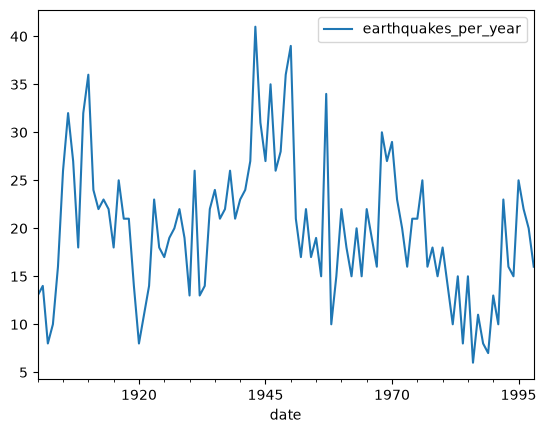

In [35]:
# Fit model
model = ARIMA(earthquake, order=(1,0,1))
results = model.fit()

# Calculate the mean absolute error from residuals
mae = np.mean(np.abs(results.resid))

# Print mean absolute error
print(mae)

# Make plot of time series for comparison
earthquake.plot()
plt.show()

##############################################################################################################################################

In [36]:
# Semilla
np.random.seed(42)

# Fechas
dates = pd.date_range(
    start='2013-01-01',
    periods=1000,
    freq='D'
)

# Coeficientes verdaderos
# y_t = 0.6 y_{t-1} -0.4 y_{t-2} +0.2 y_{t-3}
#       + e_t +0.5 e_{t-1} -0.3 e_{t-2}

ar = [1, -0.6, 0.4, -0.2]
ma = [1, 0.5, -0.3]

# Generar serie
y = arma_generate_sample(
    ar=ar,
    ma=ma,
    nsample=len(dates),
    scale=1
)

# DataFrame
df = pd.DataFrame(
    {'y': y},
    index=dates
)

df.index.name = 'date'

df.head()

,y
date,
2013-01-01,0.496714
2013-01-02,0.408121
2013-01-03,0.475729
2013-01-04,2.109885
2013-01-05,1.490319


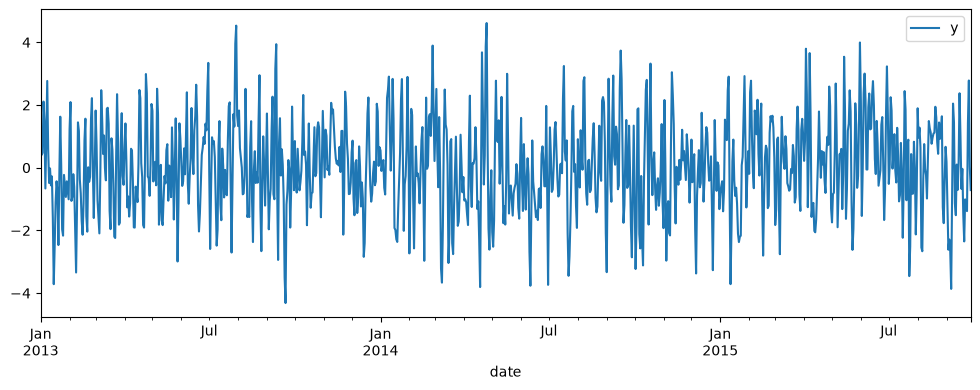

In [37]:
df.plot(figsize=(12,4))
plt.show()

In [38]:
import warnings

warnings.filterwarnings('ignore')

order_aic_bic = []

for p in range(8):
    for q in range(8):

        try:
            model = ARIMA(
                df['y'],
                order=(p,0,q)
            )

            results = model.fit()

            order_aic_bic.append(
                (
                    p,
                    q,
                    results.aic,
                    results.bic
                )
            )

        except:
            continue

In [39]:
order_df = pd.DataFrame(
    order_aic_bic,
    columns=['p','q','AIC','BIC']
)

print("Mejores según AIC")
print(
    order_df
    .sort_values('AIC')
    .head(10)
)

print("\nMejores según BIC")
print(
    order_df
    .sort_values('BIC')
    .head(10)
)

Mejores según AIC
    p  q          AIC          BIC
25  3  1  2804.671445  2834.117977
18  2  2  2804.854329  2834.300861
17  2  1  2805.343858  2829.882634
26  3  2  2805.889620  2840.243906
5   0  5  2806.353344  2840.707631
33  4  1  2806.595282  2840.949569
36  4  4  2806.714171  2855.791724
19  2  3  2806.788333  2841.142620
20  2  4  2807.019517  2846.281559
43  5  3  2807.049787  2856.127340

Mejores según BIC
    p  q          AIC          BIC
17  2  1  2805.343858  2829.882634
3   0  3  2808.383355  2832.922131
25  3  1  2804.671445  2834.117977
18  2  2  2804.854329  2834.300861
4   0  4  2809.163200  2838.609732
11  1  3  2809.683332  2839.129864
26  3  2  2805.889620  2840.243906
5   0  5  2806.353344  2840.707631
33  4  1  2806.595282  2840.949569
19  2  3  2806.788333  2841.142620


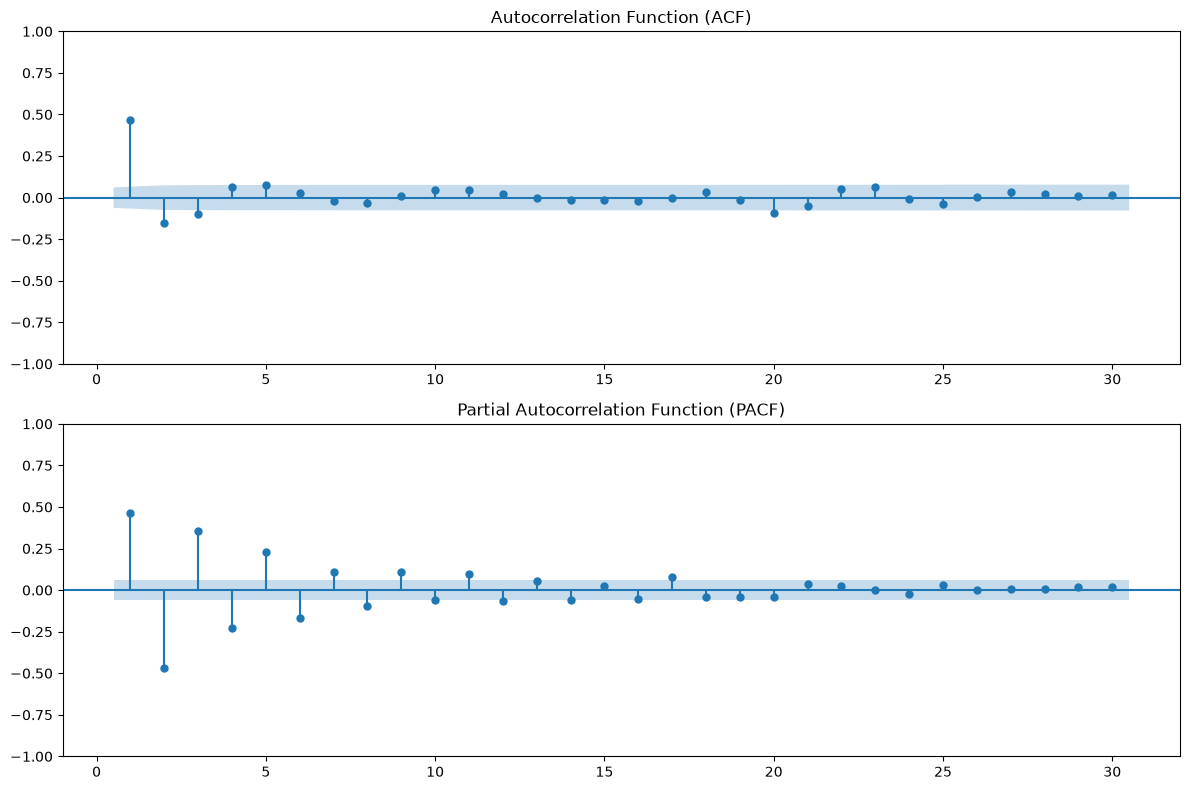

In [40]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# Crear figura
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(12, 8)
)

# ACF
plot_acf(
    df['y'],
    lags=30,
    zero=False,
    ax=ax1
)
ax1.set_title('Autocorrelation Function (ACF)')

# PACF
plot_pacf(
    df['y'],
    lags=30,
    zero=False,
    ax=ax2,
    method='ywm'
)
ax2.set_title('Partial Autocorrelation Function (PACF)')

plt.tight_layout()
plt.show()

In [41]:
# Create and fit model
model1 = ARIMA(df, order=(3,0,1))
results1 = model1.fit()

# Print summary
print(results1.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1000
Model:                 ARIMA(3, 0, 1)   Log Likelihood               -1396.336
Date:                Wed, 15 Jul 2026   AIC                           2804.671
Time:                        12:35:54   BIC                           2834.118
Sample:                    01-01-2013   HQIC                          2815.863
                         - 09-27-2015                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0382      0.058      0.655      0.513      -0.076       0.152
ar.L1          0.2096      0.037      5.694      0.000       0.137       0.282
ar.L2         -0.2735      0.036     -7.639      0.0

# Interpretación del resumen del ARIMA(3,0,1)

## Parámetros del modelo

- **const = 0.038 (p-value = 0.513)** → no es significativo.
- **ar.L1 = 0.210 (p-value < 0.001)** → es significativo.
- **ar.L2 = -0.274 (p-value < 0.001)** → es significativo.
- **ar.L3 = 0.057 (p-value = 0.113)** → no es significativo.
- **ma.L1 = 0.886 (p-value < 0.001)** → es significativo.

Por lo tanto, el modelo podría simplificarse eliminando el término constante y posiblemente el término **AR(3)**.

---

## Calidad del ajuste

- **AIC = 2804.67**
- **BIC = 2834.12**
- **HQIC = 2815.86**

Estos criterios se utilizan para **comparar modelos**; cuanto menores sean sus valores, mejor es el compromiso entre ajuste y complejidad.

---

## Diagnóstico de residuos

### Ljung-Box
- **Prob(Q) = 0.99 > 0.05**

✅ No se rechaza la hipótesis nula de ausencia de autocorrelación.

Los residuos se comportan como **ruido blanco**, indicando que el modelo capturó adecuadamente la dependencia temporal de la serie.

---

### Jarque-Bera
- **Prob(JB) = 0.23 > 0.05**

✅ No hay evidencia suficiente para rechazar la normalidad de los residuos.

---

### Heterocedasticidad
- **Prob(H) = 0.79 > 0.05**

✅ No hay evidencia de heterocedasticidad; la varianza de los residuos puede considerarse constante.

---

# Conclusión

> El modelo **ARIMA(3,0,1)** presenta un ajuste adecuado y sus residuos cumplen razonablemente los supuestos de ruido blanco, normalidad y homocedasticidad. Sin embargo, dado que el término constante y el coeficiente **AR(3)** no son estadísticamente significativos, podría evaluarse un modelo más parsimonioso, como un **ARIMA(2,0,1)**, y comparar sus métricas (**AIC**, **BIC**) para determinar si ofrece un desempeño similar con menor complejidad.

In [42]:
# Create and fit model
model2 = ARIMA(df, order=(2,0,1))
results2 = model2.fit()

# Print summary
print(results2.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1000
Model:                 ARIMA(2, 0, 1)   Log Likelihood               -1397.672
Date:                Wed, 15 Jul 2026   AIC                           2805.344
Time:                        12:35:54   BIC                           2829.883
Sample:                    01-01-2013   HQIC                          2814.670
                         - 09-27-2015                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0380      0.055      0.687      0.492      -0.070       0.147
ar.L1          0.1859      0.034      5.475      0.000       0.119       0.252
ar.L2         -0.2543      0.034     -7.469      0.0

### Diagnóstico de residuos

- **Ljung-Box:** `Prob(Q) = 0.69 > 0.05`

✅ No se rechaza la hipótesis nula de ausencia de autocorrelación. Los residuos no presentan autocorrelación significativa, lo que indica que el modelo ha capturado adecuadamente la dependencia temporal de la serie.

- **Jarque-Bera:** `Prob(JB) = 0.23 > 0.05`

✅ No se rechaza la hipótesis nula de normalidad. Los residuos son compatibles con una distribución aproximadamente normal.

- **Heterocedasticidad:** `Prob(H) = 0.75 > 0.05`

✅ No se rechaza la hipótesis nula de homocedasticidad. No hay evidencia de varianza no constante en los residuos.

### Conclusión

> Los residuos se comportan razonablemente como **ruido blanco gaussiano**, ya que no presentan autocorrelación significativa, son aproximadamente normales y exhiben varianza constante. En consecuencia, el modelo **ARIMA(2,0,1)** parece proporcionar un ajuste adecuado desde el punto de vista de los diagnósticos residuales.

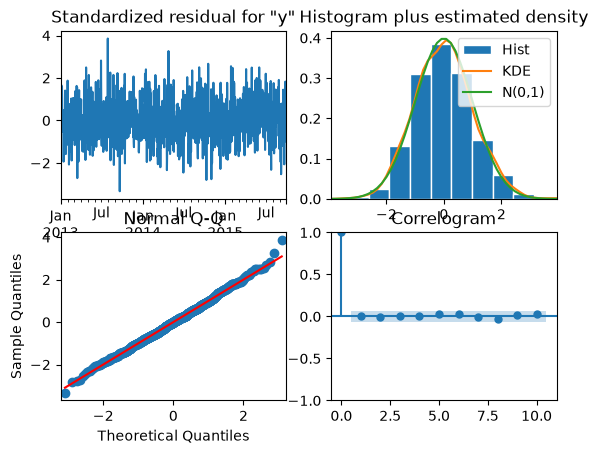

In [43]:
# Create and fit model
model = ARIMA(df, order=(3,0,1))
results = model.fit()

# Create the 4 diagnostics plots
results.plot_diagnostics()
plt.show()

## Diagnóstico del modelo ARIMA(3,0,1)

### 1. Residuos estandarizados
✅ No se observan patrones evidentes, tendencias ni cambios de varianza.

> Los residuos parecen comportarse como ruido blanco.

---

### 2. Histograma + KDE
✅ La curva KDE es muy similar a la distribución normal teórica.

> Los residuos tienen una distribución aproximadamente normal.

---

### 3. Normal Q-Q
✅ La mayoría de los puntos se encuentran sobre la línea recta.

> La hipótesis de normalidad de los residuos parece razonable, con pequeñas desviaciones en las colas.

---

### 4. Correlograma (ACF de residuos)
✅ Casi todas las autocorrelaciones están dentro de las bandas de confianza.

> No queda dependencia temporal significativa en los residuos.

---

## Conclusión

> El modelo **ARIMA(1,1,1)** parece estar bien especificado. Los residuos se comportan aproximadamente como **ruido blanco gaussiano** (sin autocorrelación, aproximadamente normales y sin patrones visibles), lo que indica un buen ajuste del modelo a la serie temporal.

## Metódología de Box - Jenkins

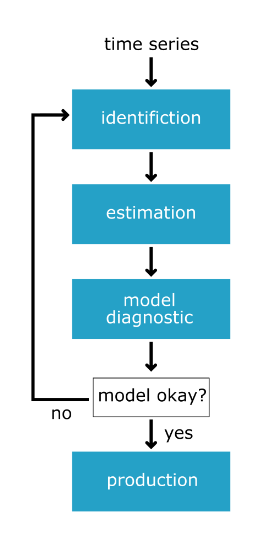